# 06 · Monthly-stay price model

**Question:** the fair-price model in 02 learned from normal stays only. About a third of Istanbul's listings are **monthly rentals** (minimum stay 28 nights or more), and they price differently. What is a fair nightly price for *them*?

Why it matters for the app: before this notebook, Explore applied the normal-stay model to monthly listings, so they looked about 35% "below fair" and filled the list of best deals. Now Explore has a *Stay length* switch, and monthly stays are compared with a model trained on monthly stays.

**Plan**
1. Load the monthly listings and split train/test (same features as 02)
2. Baselines: district × stay type median, and the normal-stay model from 02
3. XGBoost trained on monthly listings (02's tuned settings, and a smaller version)
4. Compare, plot predicted vs actual
5. Out-of-fold fair price for every monthly listing + save

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, cross_val_predict
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

ROOT = Path("..").resolve()
PROCESSED = ROOT / "data" / "processed"
MODELS = ROOT / "models"
FIGS = ROOT / "reports" / "figures"
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42

## 1. Load and split

In [2]:
df_all = pd.read_parquet(PROCESSED / "listings_clean.parquet")
feats = json.load(open(PROCESSED / "feature_lists.json"))
CAT, NUM = feats["cat"], feats["num"]

mo = df_all[df_all["is_monthly"] == 1].reset_index(drop=True)
X, y = mo[CAT + NUM], mo["log_price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"monthly listings {len(mo):,} · train {len(X_train):,} · test {len(X_test):,}")
print(f"median nightly price: monthly ₺{mo['price'].median():,.0f} vs normal ₺{df_all.loc[df_all['is_monthly'] == 0, 'price'].median():,.0f}")

monthly listings 7,754 · train 6,203 · test 1,551
median nightly price: monthly ₺2,168 vs normal ₺4,459


In [3]:
results = {}
LOG_MIN, LOG_MAX = y_train.min(), y_train.max()

def evaluate(name, y_true_log, y_pred_log):
    y_pred_log = np.clip(y_pred_log, LOG_MIN, LOG_MAX)
    y_true, y_pred = np.exp(y_true_log), np.exp(y_pred_log)
    results[name] = {
        "RMSE_log": np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        "MAE_TRY": mean_absolute_error(y_true, y_pred),
        "MedianAPE_%": np.median(np.abs(y_pred / y_true - 1)) * 100,
        "R2_log": r2_score(y_true_log, y_pred_log),
    }
    print(name, {k: round(v, 3) for k, v in results[name].items()})

## 2. Baselines
The district × stay type median, and the normal-stay model from 02 used as it is. The second one is what Explore did before.

In [4]:
grp = ["neighbourhood_cleansed", "stay_type"]
med_grp = X_train.assign(y=y_train).groupby(grp)["y"].median()
base_pred = X_test.join(med_grp.rename("p"), on=grp)["p"].fillna(y_train.median())
evaluate("Baseline (median)", y_test, base_pred)

normal_model = joblib.load(MODELS / "price_model.joblib")
evaluate("Normal-stay model (02)", y_test, normal_model.predict(X_test))

Baseline (median) {'RMSE_log': np.float64(0.738), 'MAE_TRY': 1966.53, 'MedianAPE_%': np.float64(43.387), 'R2_log': 0.238}
Normal-stay model (02) {'RMSE_log': np.float64(0.805), 'MAE_TRY': 2247.026, 'MedianAPE_%': np.float64(63.52), 'R2_log': 0.094}


## 3. XGBoost on monthly listings
Same pipeline and tuned settings as 02, trained only on monthly listings. There are about 3 times fewer of them, so we also try a smaller model that is less likely to overfit.

In [5]:
xgb_m = clone(normal_model).fit(X_train, y_train)
evaluate("XGBoost monthly (02 settings)", y_test, xgb_m.predict(X_test))

xgb_small = clone(normal_model).set_params(model__n_estimators=600, model__max_depth=5, model__min_child_weight=5)
xgb_small.fit(X_train, y_train)
evaluate("XGBoost monthly (smaller)", y_test, xgb_small.predict(X_test))

XGBoost monthly (02 settings) {'RMSE_log': np.float64(0.6), 'MAE_TRY': 1599.741, 'MedianAPE_%': np.float64(31.485), 'R2_log': 0.496}
XGBoost monthly (smaller) {'RMSE_log': np.float64(0.599), 'MAE_TRY': 1626.496, 'MedianAPE_%': np.float64(33.88), 'R2_log': 0.499}


## 4. Compare

,RMSE_log,MAE_TRY,MedianAPE_%,R2_log
XGBoost monthly (smaller),0.599,1626.496,33.880,0.499
XGBoost monthly (02 settings),0.600,1599.741,31.485,0.496
Baseline (median),0.738,1966.530,43.387,0.238
Normal-stay model (02),0.805,2247.026,63.520,0.094


best monthly model: XGBoost monthly (smaller)


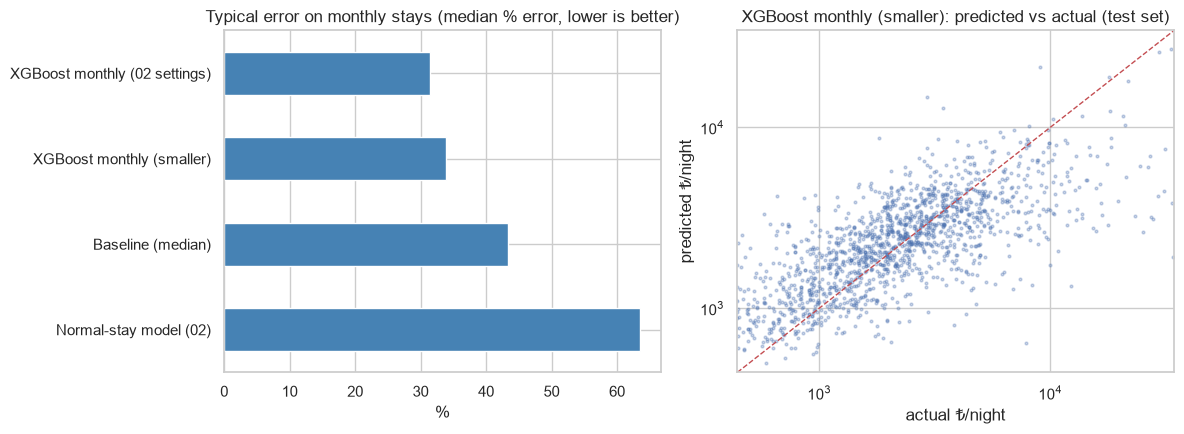

In [6]:
res = pd.DataFrame(results).T.sort_values("RMSE_log")
display(res.round(3))
candidates = {"XGBoost monthly (02 settings)": xgb_m, "XGBoost monthly (smaller)": xgb_small}
best_name = min(candidates, key=lambda k: results[k]["RMSE_log"])
BEST = candidates[best_name]
print("best monthly model:", best_name)

pred = np.exp(np.clip(BEST.predict(X_test), LOG_MIN, LOG_MAX)); actual = np.exp(y_test)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
res["MedianAPE_%"].sort_values().plot(kind="barh", ax=ax[0], color="steelblue")
ax[0].invert_yaxis(); ax[0].set(title="Typical error on monthly stays (median % error, lower is better)", xlabel="%")
ax[1].scatter(actual, pred, s=4, alpha=.3)
lim = [actual.quantile(.005), actual.quantile(.995)]
ax[1].plot(lim, lim, "r--", lw=1)
ax[1].set(xscale="log", yscale="log", xlim=lim, ylim=lim, title=f"{best_name}: predicted vs actual (test set)",
          xlabel="actual ₺/night", ylabel="predicted ₺/night")
plt.tight_layout(); plt.savefig(FIGS / "monthly_model.png", dpi=120); plt.show()

**What I see:** _how much better is a model trained on monthly stays than reusing the normal one? Is the monthly error higher than 02's, and why might that be (fewer listings, fewer reviews, many inactive)?_

## 5. Fair price for every monthly listing (out-of-fold)
As in 02: each listing is priced by a model that never saw it, so the deals aren't flattered. The app reads `listings_monthly.parquet` in Explore when *Stay length* is set to a month or more.

In [7]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
oof_log = cross_val_predict(BEST, X, y, cv=kf, n_jobs=1)
final_monthly = BEST.fit(X, y)
joblib.dump(final_monthly, MODELS / "price_model_monthly.joblib")

out = mo[["id"]].copy()
out["fair_price_m"] = np.exp(np.clip(oof_log, LOG_MIN, LOG_MAX))
out["price_gap_m"] = (out["fair_price_m"] - mo["price"]) / out["fair_price_m"]   # + = cheaper than fair
out.to_parquet(PROCESSED / "listings_monthly.parquet", index=False)

t = results[best_name]
scores = {"model": best_name, "MedianAPE_%": float(t["MedianAPE_%"]), "R2_log": float(t["R2_log"]),
          "normal_model_MedianAPE_%": float(results["Normal-stay model (02)"]["MedianAPE_%"]), "n": int(len(mo))}
json.dump(scores, open(MODELS / "monthly_scores.json", "w"), indent=1)
print("OOF RMSE_log:", np.sqrt(mean_squared_error(y, oof_log)).round(3))
print(scores)
out["price_gap_m"].describe().round(3)

OOF RMSE_log: 0.587
{'model': 'XGBoost monthly (smaller)', 'MedianAPE_%': 33.88004742973835, 'R2_log': 0.49906885350980457, 'normal_model_MedianAPE_%': 63.52014062819269, 'n': 7754}


count    7754.000
mean       -0.260
std         1.597
min       -46.498
25%        -0.332
50%         0.048
75%         0.300
max         0.861
Name: price_gap_m, dtype: float64

### Summary (fill in)
- Monthly model: _…_ (≈ _…_% typical error, R² _…_) vs _…_% when the normal-stay model was reused
- Why monthly stays are harder to price: _…_